# DeepSC Reconstruction Evaluation

This notebook runs reconstruction-only inference from the saved DeepSC checkpoint.

Workflow:
- Load config, data, and checkpoint
- Select 15-20 samples from test split
- Reconstruct at all configured SNR values
- Print all reconstructions and save CSV

In [2]:
from pathlib import Path
import random

import pandas as pd
import torch
from nltk.translate.bleu_score import sentence_bleu

import deepsc_replication as ds

In [3]:
ROOT = Path.cwd()
if not (ROOT / "deepsc_replication_config.json").exists():
    ROOT = ROOT / "btp_env"

config = ds.load_config(ROOT / "deepsc_replication_config.json")
seed = int(config["dataset"]["seed"])
ds.set_seed(seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

loaders, stoi, itos, pad_id, token_ids, max_seq_len = ds.load_repo_data(config, ROOT)
snr_values = config["channel"]["eval_snr_db"]
print("SNR list:", snr_values)
print("Test samples:", len(loaders["test"].dataset))

model_cfg = config["model"]
model_max_len = max(int(config["dataset"]["max_len"]), int(max_seq_len))

model = ds.DeepSCBaseline(
    vocab_size=len(stoi),
    d_model=int(model_cfg["d_model"]),
    nhead=int(model_cfg["nhead"]),
    num_enc_layers=int(model_cfg["num_enc_layers"]),
    num_dec_layers=int(model_cfg["num_dec_layers"]),
    dim_feedforward=int(model_cfg["dim_feedforward"]),
    channel_dim=int(model_cfg["channel_dim"]),
    channel_hidden=int(model_cfg["channel_hidden"]),
    channel_decoder_hidden=int(model_cfg["channel_decoder_hidden"]),
    max_len=model_max_len,
    pad_id=pad_id,
    dropout=float(model_cfg["dropout"]),
).to(device)

ckpt_path = ROOT / config["artifacts"]["checkpoint"]
if not ckpt_path.exists():
    raise FileNotFoundError(f"Checkpoint not found: {ckpt_path}")

model.load_state_dict(torch.load(ckpt_path, map_location=device, weights_only=True))
model.eval()
print("Loaded checkpoint:", ckpt_path.name)

Using device: cuda
SNR list: [0, 3, 6, 9, 12, 15, 18]
Test samples: 9999
Loaded checkpoint: deepsc_best.pt


In [4]:
special_ids = {token_ids["pad"], token_ids["start"], token_ids["end"], token_ids["unk"]}
unk_token = config["dataset"]["special_tokens"][3]

@torch.no_grad()
def reconstruct_one(encoded_ids, snr_db):
    input_ids = torch.tensor(encoded_ids, dtype=torch.long, device=device).unsqueeze(0)
    attention_mask = torch.ones_like(input_ids)

    noise_std = ds.snr_to_noise_std(float(snr_db))
    out_ids = model.generate(
        input_ids=input_ids,
        attention_mask=attention_mask,
        noise_std=noise_std,
        sos_id=token_ids["start"],
        eos_id=token_ids["end"],
    )

    ref_tokens = ds.decode_tokens(encoded_ids, itos, special_ids, token_ids["end"], unk_token)
    hyp_tokens = ds.decode_tokens(out_ids.squeeze(0).tolist(), itos, special_ids, token_ids["end"], unk_token)

    reference = " ".join(ref_tokens)
    hypothesis = " ".join(hyp_tokens) if hyp_tokens else "<empty>"

    hyp_for_bleu = hyp_tokens if hyp_tokens else ["the"]
    if ref_tokens:
        bleu1 = sentence_bleu([ref_tokens], hyp_for_bleu, weights=(1.0, 0, 0, 0))
        bleu2 = sentence_bleu([ref_tokens], hyp_for_bleu, weights=(0.5, 0.5, 0, 0))
        bleu3 = sentence_bleu([ref_tokens], hyp_for_bleu, weights=(1 / 3, 1 / 3, 1 / 3, 0))
        bleu4 = sentence_bleu([ref_tokens], hyp_for_bleu, weights=(0.25, 0.25, 0.25, 0.25))
    else:
        bleu1 = bleu2 = bleu3 = bleu4 = 0.0

    return reference, hypothesis, float(bleu1), float(bleu2), float(bleu3), float(bleu4)

In [4]:
# Choose reconstruction sample count in [15, 20]
NUM_RECON_SAMPLES = 20
RANDOM_SAMPLE = True

test_encoded = loaders["test"].dataset.encoded_samples
total_test = len(test_encoded)
num_take = min(int(NUM_RECON_SAMPLES), total_test)

if RANDOM_SAMPLE:
    rng = random.Random(seed)
    selected_indices = rng.sample(range(total_test), k=num_take)
else:
    selected_indices = list(range(num_take))

rows = []
for i, idx in enumerate(selected_indices, start=1):
    encoded_ids = test_encoded[idx]
    for snr in snr_values:
        reference, hypothesis, bleu1, bleu2, bleu3, bleu4 = reconstruct_one(encoded_ids, snr)
        rows.append({
            "sample_idx": int(idx),
            "snr_db": float(snr),
            "reference": reference,
            "hypothesis": hypothesis,
            "bleu1": bleu1,
            "bleu2": bleu2,
            "bleu3": bleu3,
            "bleu4": bleu4,
        })

    if i % 5 == 0 or i == num_take:
        print(f"Processed {i}/{num_take} selected samples")

recon_df = pd.DataFrame(rows).sort_values(["sample_idx", "snr_db"]).reset_index(drop=True)
print("Selected samples:", num_take)
print("Rows:", len(recon_df))
recon_df.head()

d:\btp_reso\btp_env\Lib\site-packages\torch\nn\modules\transformer.py:502: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\aten\src\ATen\NestedTensorImpl.cpp:180.)
  output = torch._nested_tensor_from_mask(
d:\btp_reso\btp_env\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 4-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
d:\btp_reso\btp_env\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 3-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  w

Processed 5/20 selected samples
Processed 10/20 selected samples
Processed 15/20 selected samples


d:\btp_reso\btp_env\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 2-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)


Processed 20/20 selected samples
Selected samples: 20
Rows: 140


,sample_idx,snr_db,reference,hypothesis,bleu1,bleu2,bleu3,bleu4
0,409,0.0,"thank you , mr falconer i have made a note of it","thank you , mr falconer i have a at report of it",0.833333,0.728219,0.642438,0.585906
1,409,3.0,"thank you , mr falconer i have made a note of it","thank you , mr falconer i have made a note of it",1.000000,1.000000,1.000000,1.000000
2,409,6.0,"thank you , mr falconer i have made a note of it","thank you , mr falconer i have made a note of it",1.000000,1.000000,1.000000,1.000000
3,409,9.0,"thank you , mr falconer i have made a note of it","thank you , mr falconer i have made a note of it",1.000000,1.000000,1.000000,1.000000
4,409,12.0,"thank you , mr falconer i have made a note of it","thank you , mr falconer i have made a note of it",1.000000,1.000000,1.000000,1.000000


In [5]:
# Print all reconstructed samples
if recon_df.empty:
    print("No reconstructions found. Run previous cell first.")
else:
    for sample_idx in sorted(recon_df["sample_idx"].unique().tolist()):
        sample_df = recon_df[recon_df["sample_idx"] == sample_idx].sort_values("snr_db")
        print("=" * 120)
        print("Sample:", sample_idx)
        print("Reference:", sample_df["reference"].iloc[0])
        for _, row in sample_df.iterrows():
            print(
                f"SNR {int(row['snr_db']):>2} dB | "
                f"B1={row['bleu1']:.4f} B2={row['bleu2']:.4f} "
                f"B3={row['bleu3']:.4f} B4={row['bleu4']:.4f} | {row['hypothesis']}"
            )

Sample: 409
Reference: thank you , mr falconer i have made a note of it
SNR  0 dB | B1=0.8333 B2=0.7282 B3=0.6424 B4=0.5859 | thank you , mr falconer i have a at report of it
SNR  3 dB | B1=1.0000 B2=1.0000 B3=1.0000 B4=1.0000 | thank you , mr falconer i have made a note of it
SNR  6 dB | B1=1.0000 B2=1.0000 B3=1.0000 B4=1.0000 | thank you , mr falconer i have made a note of it
SNR  9 dB | B1=1.0000 B2=1.0000 B3=1.0000 B4=1.0000 | thank you , mr falconer i have made a note of it
SNR 12 dB | B1=1.0000 B2=1.0000 B3=1.0000 B4=1.0000 | thank you , mr falconer i have made a note of it
SNR 15 dB | B1=1.0000 B2=1.0000 B3=1.0000 B4=1.0000 | thank you , mr falconer i have made a note of it
SNR 18 dB | B1=1.0000 B2=1.0000 B3=1.0000 B4=1.0000 | thank you , mr falconer i have made a note of it
Sample: 434
Reference: mr martinez , you are an admirable jurist you know that this is not the right time for explanations of vote , which are at the end
SNR  0 dB | B1=0.1061 B2=0.0498 B3=0.0000 B4=0.0000 |

In [6]:
out_csv = ROOT / "deepsc_reconstruction_samples_all_snrs.csv"
recon_df.to_csv(out_csv, index=False)
print("Saved:", out_csv)

summary = (
    recon_df.groupby("snr_db", as_index=False)[["bleu1", "bleu2", "bleu3", "bleu4"]]
    .mean()
    .rename(
        columns={
            "bleu1": "avg_sentence_bleu1",
            "bleu2": "avg_sentence_bleu2",
            "bleu3": "avg_sentence_bleu3",
            "bleu4": "avg_sentence_bleu4",
        }
    )
)
summary

Saved: d:\btp_reso\btp_env\deepsc_reconstruction_samples_all_snrs.csv


,snr_db,avg_sentence_bleu1,avg_sentence_bleu2,avg_sentence_bleu3,avg_sentence_bleu4
0,0.0,0.420220,0.281090,0.198122,0.134729
1,3.0,0.599288,0.515437,0.447127,0.411433
2,6.0,0.828929,0.758437,0.695062,0.651919
3,9.0,0.893312,0.836097,0.783590,0.749230
4,12.0,0.905086,0.855455,0.810157,0.782535
5,15.0,0.906217,0.858471,0.815111,0.789873
6,18.0,0.926134,0.883494,0.850726,0.807567


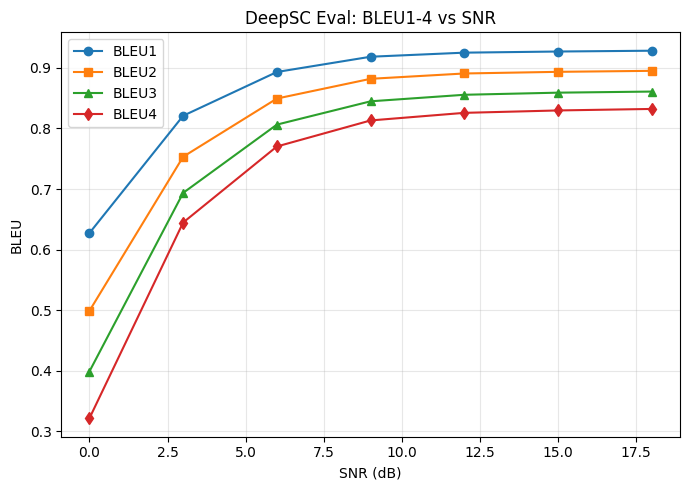

Saved: d:\btp_reso\btp_env\deepsc_results_all_bleu_latest.png


In [7]:
# Fallback: generate BLEU1-4 plot PNG from evaluation CSV
import matplotlib.pyplot as plt

bleu_csv = ROOT / "deepsc_results_all_bleu_latest.csv"
bleu_png = ROOT / "deepsc_results_all_bleu_latest.png"

if not bleu_csv.exists():
    raise FileNotFoundError(f"Missing BLEU CSV: {bleu_csv}")

bleu_df = pd.read_csv(bleu_csv)
required_cols = ["snr_db", "bleu1", "bleu2", "bleu3", "bleu4"]
missing = [c for c in required_cols if c not in bleu_df.columns]
if missing:
    raise ValueError(f"Missing expected columns in BLEU CSV: {missing}")

plt.figure(figsize=(7, 5))
markers = ["o", "s", "^", "d"]
for i, metric in enumerate(["bleu1", "bleu2", "bleu3", "bleu4"]):
    plt.plot(bleu_df["snr_db"], bleu_df[metric], marker=markers[i], label=metric.upper())

plt.xlabel("SNR (dB)")
plt.ylabel("BLEU")
plt.title("DeepSC Eval: BLEU1-4 vs SNR")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(bleu_png, dpi=150, bbox_inches="tight")
plt.show()

print("Saved:", bleu_png)

In [5]:
@torch.no_grad()
def reconstruct_one(encoded_ids, snr_db):
    input_ids = torch.tensor(encoded_ids, dtype=torch.long, device=device).unsqueeze(0)
    attention_mask = torch.ones_like(input_ids)

    noise_std = ds.snr_to_noise_std(float(snr_db))
    out_ids = model.generate(
        input_ids=input_ids,
        attention_mask=attention_mask,
        noise_std=noise_std,
        sos_id=token_ids["start"],
        eos_id=token_ids["end"],
    )

    ref_tokens = ds.decode_tokens(encoded_ids, itos, special_ids, token_ids["end"], unk_token)
    hyp_tokens = ds.decode_tokens(out_ids.squeeze(0).tolist(), itos, special_ids, token_ids["end"], unk_token)

    reference = " ".join(ref_tokens)
    hypothesis = " ".join(hyp_tokens) if hyp_tokens else "<empty>"

    hyp_for_bleu = hyp_tokens if hyp_tokens else ["the"]
    if ref_tokens:
        bleu1 = sentence_bleu([ref_tokens], hyp_for_bleu, weights=(1.0, 0, 0, 0))
        bleu2 = sentence_bleu([ref_tokens], hyp_for_bleu, weights=(0.5, 0.5, 0, 0))
        bleu3 = sentence_bleu([ref_tokens], hyp_for_bleu, weights=(1/3, 1/3, 1/3, 0))
        bleu4 = sentence_bleu([ref_tokens], hyp_for_bleu, weights=(0.25, 0.25, 0.25, 0.25))
    else:
        bleu1 = bleu2 = bleu3 = bleu4 = 0.0

    return reference, hypothesis, float(bleu1), float(bleu2), float(bleu3), float(bleu4)

d:\btp_reso\btp_env\Lib\site-packages\torch\nn\modules\transformer.py:502: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\aten\src\ATen\NestedTensorImpl.cpp:180.)
  output = torch._nested_tensor_from_mask(
d:\btp_reso\btp_env\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 3-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
d:\btp_reso\btp_env\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 4-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  w

Processed 1000/9999 test samples
Processed 2000/9999 test samples
Processed 3000/9999 test samples
Processed 4000/9999 test samples
Processed 5000/9999 test samples
Processed 6000/9999 test samples
Processed 7000/9999 test samples
Processed 8000/9999 test samples
Processed 9000/9999 test samples
Processed 9999/9999 test samples
Collected 9999 per-sentence BLEU scores at SNR 6.0 dB
Saved: deepsc_bleu1234_sentence_snr6_all_test.csv


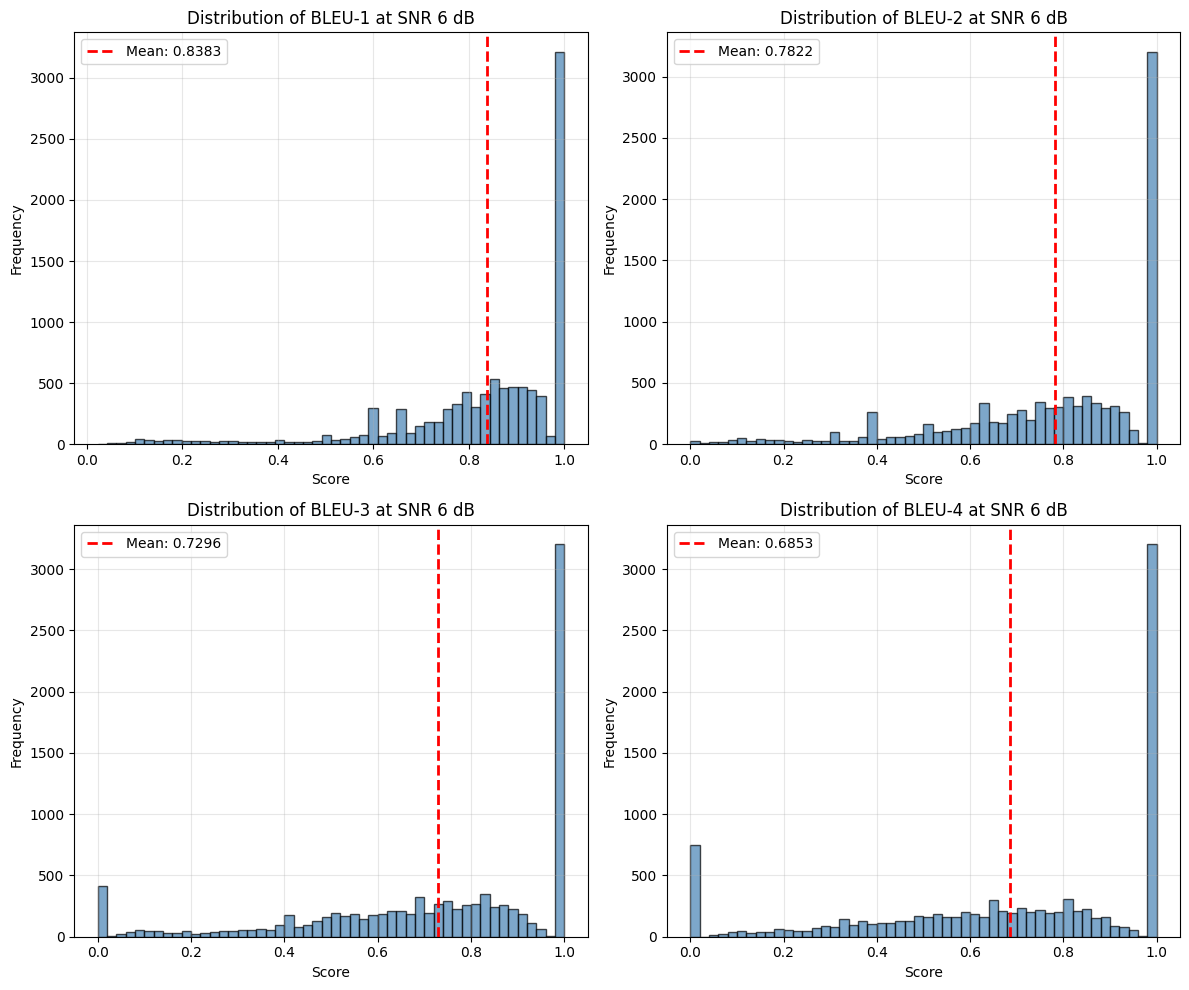


BLEU Score Statistics at SNR 6.0 dB (DeepSC, all test):
BLEU1 — Mean: 0.8383, Std: 0.1892, Min: 0.0232, Max: 1.0000
BLEU2 — Mean: 0.7822, Std: 0.2292, Min: 0.0000, Max: 1.0000
BLEU3 — Mean: 0.7296, Std: 0.2792, Min: 0.0000, Max: 1.0000
BLEU4 — Mean: 0.6853, Std: 0.3123, Min: 0.0000, Max: 1.0000

Saved: deepsc_bleu1234_distribution_snr6_all_test.png


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- Distribution of BLEU-1/2/3/4 scores at SNR 6 dB for DeepSC (ALL test samples) ----
snr_db = 6.0
test_encoded = loaders["test"].dataset.encoded_samples  # all test samples

bleu1_scores = []
bleu2_scores = []
bleu3_scores = []
bleu4_scores = []

for idx, encoded_ids in enumerate(test_encoded, start=1):
    # reconstruct_one comes from your DeepSC notebook and already computes BLEU1..4
    _, _, b1, b2, b3, b4 = reconstruct_one(encoded_ids, snr_db)

    bleu1_scores.append(b1)
    bleu2_scores.append(b2)
    bleu3_scores.append(b3)
    bleu4_scores.append(b4)

    if idx % 1000 == 0 or idx == len(test_encoded):
        print(f"Processed {idx}/{len(test_encoded)} test samples")

print(f"Collected {len(bleu1_scores)} per-sentence BLEU scores at SNR {snr_db} dB")

# Optional: save per-sentence BLEU scores
df_sent = pd.DataFrame({
    "snr_db": [snr_db] * len(bleu1_scores),
    "bleu1": bleu1_scores,
    "bleu2": bleu2_scores,
    "bleu3": bleu3_scores,
    "bleu4": bleu4_scores,
})
df_sent.to_csv("deepsc_bleu1234_sentence_snr6_all_test.csv", index=False)
print("Saved: deepsc_bleu1234_sentence_snr6_all_test.csv")

# ---- Plot (same style as semantic/traditional) ----
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

all_scores = [bleu1_scores, bleu2_scores, bleu3_scores, bleu4_scores]
titles = [
    "Distribution of BLEU-1 at SNR 6 dB",
    "Distribution of BLEU-2 at SNR 6 dB",
    "Distribution of BLEU-3 at SNR 6 dB",
    "Distribution of BLEU-4 at SNR 6 dB",
]

for i, (scores, title) in enumerate(zip(all_scores, titles)):
    mean_score = np.mean(scores)

    axes[i].hist(scores, bins=50, color="steelblue", edgecolor="black", alpha=0.7)
    axes[i].axvline(mean_score, color="red", linestyle="--", linewidth=2, label=f"Mean: {mean_score:.4f}")
    axes[i].set_xlabel("Score")
    axes[i].set_ylabel("Frequency")
    axes[i].set_title(title)
    axes[i].legend()
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("deepsc_bleu1234_distribution_snr6_all_test.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\nBLEU Score Statistics at SNR {snr_db} dB (DeepSC, all test):")
print(f"BLEU1 — Mean: {np.mean(bleu1_scores):.4f}, Std: {np.std(bleu1_scores):.4f}, Min: {np.min(bleu1_scores):.4f}, Max: {np.max(bleu1_scores):.4f}")
print(f"BLEU2 — Mean: {np.mean(bleu2_scores):.4f}, Std: {np.std(bleu2_scores):.4f}, Min: {np.min(bleu2_scores):.4f}, Max: {np.max(bleu2_scores):.4f}")
print(f"BLEU3 — Mean: {np.mean(bleu3_scores):.4f}, Std: {np.std(bleu3_scores):.4f}, Min: {np.min(bleu3_scores):.4f}, Max: {np.max(bleu3_scores):.4f}")
print(f"BLEU4 — Mean: {np.mean(bleu4_scores):.4f}, Std: {np.std(bleu4_scores):.4f}, Min: {np.min(bleu4_scores):.4f}, Max: {np.max(bleu4_scores):.4f}")
print("\nSaved: deepsc_bleu1234_distribution_snr6_all_test.png")

In [8]:
# Quick check of saved reconstruction samples
recon_csv = ROOT / "deepsc_reconstruction_samples_all_snrs.csv"
if not recon_csv.exists():
    raise FileNotFoundError(f"Missing reconstruction CSV: {recon_csv}")

recon_saved_df = pd.read_csv(recon_csv)
print("Rows:", len(recon_saved_df))
print("Unique samples:", recon_saved_df["sample_idx"].nunique())
print("Unique SNRs:", sorted(recon_saved_df["snr_db"].unique().tolist()))
recon_saved_df.head(10)

Rows: 140
Unique samples: 20
Unique SNRs: [0.0, 3.0, 6.0, 9.0, 12.0, 15.0, 18.0]


,sample_idx,snr_db,reference,hypothesis,bleu1,bleu2,bleu3,bleu4
0,409,0.0,"thank you , mr falconer i have made a note of it","thank you , mr falconer i have a at report of it",0.833333,0.728219,6.424382e-01,5.859059e-01
1,409,3.0,"thank you , mr falconer i have made a note of it","thank you , mr falconer i have made a note of it",1.000000,1.000000,1.000000e+00,1.000000e+00
2,409,6.0,"thank you , mr falconer i have made a note of it","thank you , mr falconer i have made a note of it",1.000000,1.000000,1.000000e+00,1.000000e+00
3,409,9.0,"thank you , mr falconer i have made a note of it","thank you , mr falconer i have made a note of it",1.000000,1.000000,1.000000e+00,1.000000e+00
4,409,12.0,"thank you , mr falconer i have made a note of it","thank you , mr falconer i have made a note of it",1.000000,1.000000,1.000000e+00,1.000000e+00
5,409,15.0,"thank you , mr falconer i have made a note of it","thank you , mr falconer i have made a note of it",1.000000,1.000000,1.000000e+00,1.000000e+00
6,409,18.0,"thank you , mr falconer i have made a note of it","thank you , mr falconer i have made a note of it",1.000000,1.000000,1.000000e+00,1.000000e+00
7,434,0.0,"mr martinez , you are an admirable jurist you ...","bg rule , you we an ashton and the item that",0.106139,0.049784,2.343902e-104,1.608294e-155
8,434,3.0,"mr martinez , you are an admirable jurist you ...","mr martinez , you are the report commission on...",0.777778,0.733799,6.861757e-01,6.339704e-01
9,434,6.0,"mr martinez , you are an admirable jurist you ...","mr martinez , you are an commission commission...",0.851238,0.789006,7.364139e-01,6.954495e-01


In [16]:
# User sentence reconstruction at all SNRs with BLEU1-4
from deepsc_preprocess import normalize_text, tokenize

USER_SENTENCE = "Members of the European Parliament gathered to debate economic reforms, environmental policies, and digital regulations, ensuring democratic representation while balancing national interests with collective goals across the European Union."

if not USER_SENTENCE.strip():
    raise ValueError("USER_SENTENCE is empty. Please provide a sentence.")

pad_tok, start_tok, end_tok, unk_tok = config["dataset"]["special_tokens"]
punct_to_keep = config["dataset"].get("punct_to_keep", [";", ","])
punct_to_remove = config["dataset"].get("punct_to_remove", ["?", "."])

clean_text = normalize_text(USER_SENTENCE)
toks = tokenize(
    sentence=clean_text,
    start_token=start_tok,
    end_token=end_tok,
    punct_to_keep=punct_to_keep,
    punct_to_remove=punct_to_remove,
 )

# Keep sequence within model decode budget.
if len(toks) > model.max_len:
    toks = toks[: model.max_len - 1] + [end_tok]

unk_id = token_ids["unk"]
encoded_ids = [stoi.get(tok, unk_id) for tok in toks]

ref_tokens = ds.decode_tokens(encoded_ids, itos, special_ids, token_ids["end"], unk_token)
ref_text = " ".join(ref_tokens)
print("Input sentence:", USER_SENTENCE)
print("Normalized/reference:", ref_text)

rows_user = []
for snr in snr_values:
    reference, hypothesis, bleu1, bleu2, bleu3, bleu4 = reconstruct_one(encoded_ids, snr)
    rows_user.append(
        {
            "snr_db": float(snr),
            "reference": reference,
            "hypothesis": hypothesis,
            "bleu1": bleu1,
            "bleu2": bleu2,
            "bleu3": bleu3,
            "bleu4": bleu4,
        }
    )

user_recon_df = pd.DataFrame(rows_user).sort_values("snr_db").reset_index(drop=True)
display(user_recon_df)

for _, row in user_recon_df.iterrows():
    print(
        f"SNR {int(row['snr_db']):>2} dB | "
        f"B1={row['bleu1']:.4f} B2={row['bleu2']:.4f} "
        f"B3={row['bleu3']:.4f} B4={row['bleu4']:.4f} | {row['hypothesis']}"
    )

Input sentence: Members of the European Parliament gathered to debate economic reforms, environmental policies, and digital regulations, ensuring democratic representation while balancing national interests with collective goals across the European Union.
Normalized/reference: members of the european parliament gathered to debate economic reforms , environmental policies , and digital regulations , ensuring democratic representation while balancing national interests with collective goals across the european union


d:\btp_reso\btp_env\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 3-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
d:\btp_reso\btp_env\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 4-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)


,snr_db,reference,hypothesis,bleu1,bleu2,bleu3,bleu4
0,0.0,members of the european parliament gathered to...,members the european the president is pointed ...,0.253826,0.122609,5.829549e-104,4.019670e-155
1,3.0,members of the european parliament gathered to...,i report and the i commend and account economi...,0.255237,0.185712,1.255842e-01,2.121247e-78
2,6.0,members of the european parliament gathered to...,members of the european parliament is to the f...,0.529180,0.403292,3.155562e-01,2.375992e-01
3,9.0,members of the european parliament gathered to...,members of the european parliament item to deb...,0.812500,0.724012,6.399616e-01,5.615185e-01
4,12.0,members of the european parliament gathered to...,members of the european parliament commend to ...,0.773998,0.722398,6.791048e-01,6.353015e-01
5,15.0,members of the european parliament gathered to...,members of the european parliament commend to ...,0.906250,0.854896,7.997878e-01,7.506711e-01
6,18.0,members of the european parliament gathered to...,members of the european parliament commission ...,0.812500,0.759350,7.147797e-01,6.699767e-01


SNR  0 dB | B1=0.2538 B2=0.1226 B3=0.0000 B4=0.0000 | members the european the president is pointed debate , subject , , from the european parliaments , , jan is think
SNR  3 dB | B1=0.2552 B2=0.1857 B3=0.1256 B4=0.0000 | i report and the i commend and account economic reforms item that the european union digital regulations ,
SNR  6 dB | B1=0.5292 B2=0.4033 B3=0.3156 B4=0.2376 | members of the european parliament is to the financial reforms , europe policies , and defence regulations , ensuring democratic representative while debate
SNR  9 dB | B1=0.8125 B2=0.7240 B3=0.6400 B4=0.5615 | members of the european parliament item to debate with march , environmental policies , and digital , , ensuring democratic initiative while the national interests with collective goals across the european union
SNR 12 dB | B1=0.7740 B2=0.7224 B3=0.6791 B4=0.6353 | members of the european parliament commend to you economic reforms , environmental policies , and digital regulations , ensuring democratic 